# EDA bổ sung cho Báo cáo tuần 4: từ điển dữ liệu, chất lượng dữ liệu, so sánh trước – sau xử lý
Notebook này đọc lại dữ liệu thô (TP.HCM + Hà Nội, 3 loại hình nhà ở) và áp dụng **đúng các bước làm sạch** của `du_doan_gia_nha.ipynb`, để định lượng từng vấn đề dữ liệu và so sánh trước – sau.

In [1]:
import glob
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.4g}")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

DATA_GLOB = (r"D:\dataset_machine_learning\.cache\huggingface\hub"
             r"\datasets--tinixai--vietnam-real-estates\snapshots\*\shard_*.parquet")
PROVINCES = ["Hồ Chí Minh", "Hà Nội"]
PROPERTY_TYPES = ["Nhà", "Căn hộ chung cư", "Biệt thự/Nhà liền kề"]
files = sorted(glob.glob(DATA_GLOB))

## 1. Quy mô toàn bộ bộ dữ liệu và phạm vi nghiên cứu

In [2]:
full_meta = pq.ParquetDataset(files)
n_full = sum(pq.ParquetFile(f).metadata.num_rows for f in files)
schema = pq.read_schema(files[0])
print(f"Toàn bộ bộ dữ liệu: {n_full:,} dòng × {len(schema.names)} cột")
scope = pq.read_table(files, columns=["province_name", "property_type_name"]).to_pandas()
print(scope["property_type_name"].value_counts().to_string())
print(f"Trong phạm vi (HCM + HN, 3 loại nhà ở): "
      f"{(scope.province_name.isin(PROVINCES) & scope.property_type_name.isin(PROPERTY_TYPES)).sum():,}")
del scope

Toàn bộ bộ dữ liệu: 3,500,744 dòng × 19 cột
property_type_name
Nhà                     1575536
Đất                      832766
Căn hộ chung cư          762800
Biệt thự/Nhà liền kề     269782
Shophouse                 59860
Trong phạm vi (HCM + HN, 3 loại nhà ở): 2,131,469


In [3]:
cols = [c for c in schema.names if c != "description"]
raw = pq.read_table(files, columns=cols,
                    filters=[("province_name", "in", PROVINCES),
                             ("property_type_name", "in", PROPERTY_TYPES)]).to_pandas()
desc_len = pq.read_table(files, columns=["description"],
                         filters=[("province_name", "in", PROVINCES),
                                  ("property_type_name", "in", PROPERTY_TYPES)]).column(0).to_pandas().str.len()
raw.shape

(2131469, 18)

## 2. Từ điển dữ liệu: kiểu, tỉ lệ thiếu, số giá trị khác nhau, ví dụ

In [4]:
dic = pd.DataFrame({
    "kiểu (parquet)": [str(schema.field(c).type) for c in cols],
    "% thiếu": [raw[c].isna().mean() * 100 for c in cols],
    "số giá trị khác nhau": [raw[c].nunique() for c in cols],
    "ví dụ": [str(raw[c].dropna().iloc[0])[:40] if raw[c].notna().any() else "" for c in cols],
}, index=cols)
print(f"description: kiểu string, % thiếu = {desc_len.isna().mean() * 100:.1f}, "
      f"độ dài trung vị = {desc_len.median():.0f} ký tự")
dic

description: kiểu string, % thiếu = 0.0, độ dài trung vị = 475 ký tự


,kiểu (parquet),% thiếu,số giá trị khác nhau,ví dụ
name,string,0,1550234,"Bán nhanh nhà 6 tầng thang máy, ngoạ lon"
property_type_name,string,0,3,Nhà
province_name,string,0,2,Hà Nội
district_name,string,3.18,52,Bắc Từ Liêm
ward_name,string,14.73,608,Phúc Diễn
street_name,string,30.49,3803,Ngọa Long
project_name,string,70.71,2407,Thái An Apartment
price,string,5.587,15774,7450000000
area,double,0,9862,37.0
floor_count,double,68.49,48,4.0


## 3. Thống kê mô tả các đặc trưng số (dữ liệu thô)

In [5]:
raw["price_num"] = pd.to_numeric(raw["price"], errors="coerce")
num_cols = ["price_num", "area", "bedroom_count", "bathroom_count", "floor_count",
            "frontage_width", "road_width", "house_depth"]
stats_raw = raw[num_cols].describe(percentiles=[.01, .25, .5, .75, .99]).T
stats_raw.loc["price_num", stats_raw.columns[1:]] /= 1e9    # giá: tỷ VND (trừ cột count)
stats_raw

,count,mean,std,min,1%,25%,50%,75%,99%,max
price_num,2.012e+06,22.52,"2,442",0,0,5.6,8.5,16.2,145,2.424e+06
area,2.131e+06,136.2,5.625e+04,3,22,50,69.8,98,480,8.2e+07
bedroom_count,1.518e+06,3.495,2.862,1,1,2,3,4,15,166
bathroom_count,1.417e+06,3.26,2.823,1,1,2,3,4,15,255
floor_count,6.716e+05,4.008,1.732,1,1,3,4,5,8,255
frontage_width,9.327e+05,21.15,"9,816",0.9,3,4,5,6,25,6.7e+06
road_width,3.446e+05,7.425,41.56,0.6,2,4,5,8,31,1.35e+04
house_depth,1.488e+04,13.35,7.681,1,4.216,9.5,12,16,33,300


## 4. Định lượng các vấn đề chất lượng dữ liệu

In [6]:
n0 = len(raw)
price_str = raw["price"]
issues = {}
issues["price lưu dạng chuỗi (string)"] = n0
issues["price không đổi được sang số"] = int((price_str.notna() & raw["price_num"].isna()).sum())
issues["price thiếu (null)"] = int(price_str.isna().sum())
issues["price = 0 (giá thỏa thuận)"] = int((raw["price_num"] == 0).sum())
issues["price ∈ (0; 300 triệu) – nghi tin thuê/giá theo m²"] = int(raw["price_num"].between(1, 3e8 - 1).sum())
issues["price > 500 tỷ"] = int((raw["price_num"] > 5e11).sum())
issues["bản ghi trùng hoàn toàn (mọi cột)"] = int(raw.drop(columns=["price_num"]).duplicated().sum())
issues["bản ghi trùng theo (tiêu đề, giá, diện tích, quận)"] = int(raw.duplicated(["name", "price", "area", "district_name"]).sum())
issues["area < 15 m² hoặc > 1000 m²"] = int((~raw["area"].between(15, 1000)).sum())
for c, (lo, hi) in {"bedroom_count": (1, 20), "bathroom_count": (1, 20), "floor_count": (1, 15),
                    "frontage_width": (1, 50), "road_width": (1, 60)}.items():
    issues[f"{c} ngoài [{lo}; {hi}]"] = int((raw[c].notna() & ~raw[c].between(lo, hi)).sum())
d = raw["house_direction"].dropna()
issues["house_direction viết dạng 'Đông - Nam' (khác 'Đông Nam')"] = int(d.str.contains(" - ").sum())
issues["house_direction ghi nhiều hướng (có dấu phẩy)"] = int(d.str.contains(",").sum())
issues["district_name là số ('7', '12'…)"] = int(raw["district_name"].dropna().str.fullmatch(r"\d+").sum())
issues["published_at lưu dạng chuỗi ISO"] = n0
title = raw["name"].fillna("").str.lower()
issues["tiêu đề chứa giá (số + 'tỷ'/'triệu') – nguy cơ rò rỉ"] = int(title.str.contains(r"\d+[\.,]?\d*\s*(?:tỷ|ty|tỉ|triệu|tr\b)").sum())
quality = pd.Series(issues, name="số bản ghi").to_frame()
quality["% trên tổng"] = quality["số bản ghi"] / n0 * 100
quality

,số bản ghi,% trên tổng
price lưu dạng chuỗi (string),2131469,100
price không đổi được sang số,0,0
price thiếu (null),119093,5.587
price = 0 (giá thỏa thuận),30134,1.414
price ∈ (0; 300 triệu) – nghi tin thuê/giá theo m²,864,0.04054
price > 500 tỷ,1736,0.08145
bản ghi trùng hoàn toàn (mọi cột),9,0.0004222
"bản ghi trùng theo (tiêu đề, giá, diện tích, quận)",508901,23.88
area < 15 m² hoặc > 1000 m²,8612,0.404
bedroom_count ngoài [1; 20],7912,0.3712


In [7]:
# Mất cân bằng (bài toán hồi quy: mất cân bằng giữa các nhóm, không phải giữa các lớp)
imb = (raw.groupby(["province_name", "property_type_name"]).size()
       .rename("số tin").to_frame().assign(**{"%": lambda t: t["số tin"] / n0 * 100}))
imb

số tin     %
province_name property_type_name                
Hà Nội        Biệt thự/Nhà liền kề   92936  4.36
              Căn hộ chung cư       303589 14.24
              Nhà                   549408 25.78
Hồ Chí Minh   Biệt thự/Nhà liền kề   62666  2.94
              Căn hộ chung cư       279948 13.13
              Nhà                   842922 39.55

## 5. Làm sạch: đúng các bước của notebook chính, ghi lại số dòng sau mỗi bước

In [8]:
steps = [("Dữ liệu thô (HCM + HN, 3 loại nhà ở)", len(raw))]
df = raw.copy()
df = df[df["price_num"].notna() & (df["price_num"] > 0)]; steps.append(("Bỏ giá thiếu / giá = 0", len(df)))
df = df.drop_duplicates(subset=["name", "price", "area", "district_name"]); steps.append(("Bỏ tin trùng lặp", len(df)))
df = df[df["price_num"].between(3e8, 5e11)]; steps.append(("Bỏ giá ngoài [0,3; 500] tỷ", len(df)))
for c, (lo, hi) in {"bedroom_count": (1, 20), "bathroom_count": (1, 20), "floor_count": (1, 15),
                    "frontage_width": (1, 50), "road_width": (1, 60)}.items():
    df.loc[df[c].notna() & ~df[c].between(lo, hi), c] = np.nan
df.loc[df["property_type_name"] == "Căn hộ chung cư", "floor_count"] = np.nan
df = df[df["area"].between(15, 1000)]; steps.append(("Bỏ diện tích ngoài [15; 1000] m²", len(df)))
df["published_at"] = pd.to_datetime(df["published_at"], format="ISO8601")
df["price_per_m2"] = df["price_num"] / df["area"] / 1e6
split = pd.Timestamp("2026-02-01")
is_train = df["published_at"] < split
bounds = (df[is_train].groupby(["province_name", "property_type_name"])["price_per_m2"]
          .quantile([0.01, 0.99]).unstack())
bounds.columns = ["lo", "hi"]
j = df.join(bounds, on=["province_name", "property_type_name"])
df = df[j["price_per_m2"].between(j["lo"], j["hi"])]; steps.append(("Bỏ giá/m² ngoài phân vị 1–99% (ngưỡng từ train)", len(df)))
funnel = pd.DataFrame(steps, columns=["bước", "số dòng còn lại"])
funnel["bị loại"] = (-funnel["số dòng còn lại"].diff()).fillna(0).astype(int)
funnel

,bước,số dòng còn lại,bị loại
0,"Dữ liệu thô (HCM + HN, 3 loại nhà ở)",2131469,0
1,Bỏ giá thiếu / giá = 0,1982242,149227
2,Bỏ tin trùng lặp,1504946,477296
3,"Bỏ giá ngoài [0,3; 500] tỷ",1502601,2345
4,Bỏ diện tích ngoài [15; 1000] m²,1496872,5729
5,Bỏ giá/m² ngoài phân vị 1–99% (ngưỡng từ train),1466822,30050


In [9]:
is_train = df["published_at"] < split
print(f"Train (06/2025–01/2026): {is_train.sum():,} | Test (02–03/2026): {(~is_train).sum():,}")
key = ["name", "area", "district_name"]
tr_keys = set(map(tuple, df.loc[is_train, key].astype(str).values))
te = df.loc[~is_train, key].astype(str)
overlap = np.mean([tuple(r) in tr_keys for r in te.values])
print(f"Tin test có (tiêu đề, diện tích, quận) đã xuất hiện ở train – tin đăng lại: {overlap:.1%}")

Train (06/2025–01/2026): 1,246,141 | Test (02–03/2026): 220,681
Tin test có (tiêu đề, diện tích, quận) đã xuất hiện ở train – tin đăng lại: 2.0%


## 6. So sánh trước – sau xử lý

In [10]:
compare = pd.DataFrame({
    "trước – trung vị": [raw["price_num"].median() / 1e9, raw["area"].median(), raw["bedroom_count"].median()],
    "trước – max": [raw["price_num"].max() / 1e9, raw["area"].max(), raw["bedroom_count"].max()],
    "trước – độ lệch (skew)": [raw["price_num"].skew(), raw["area"].skew(), raw["bedroom_count"].skew()],
    "sau – trung vị": [df["price_num"].median() / 1e9, df["area"].median(), df["bedroom_count"].median()],
    "sau – max": [df["price_num"].max() / 1e9, df["area"].max(), df["bedroom_count"].max()],
    "sau – độ lệch (skew)": [df["price_num"].skew(), df["area"].skew(), df["bedroom_count"].skew()],
}, index=["giá (tỷ)", "diện tích (m²)", "số phòng ngủ"])
print(f"log(giá) sau xử lý: skew = {np.log(df['price_num']).skew():.2f}")
compare

log(giá) sau xử lý: skew = 0.74


,trước – trung vị,trước – max,trước – độ lệch (skew),sau – trung vị,sau – max,sau – độ lệch (skew)
giá (tỷ),8.5,2.424e+06,887.6,8.6,500,6.214
diện tích (m²),69.8,8.2e+07,"1,454",68,"1,000",4.6
số phòng ngủ,3,166,10.39,3,20,3.6


In [11]:
miss = pd.DataFrame({"trước (%)": raw[num_cols[1:] + ["house_direction", "district_name"]].isna().mean() * 100,
                     "sau làm sạch (%)": df[num_cols[1:] + ["house_direction", "district_name"]].isna().mean() * 100})
miss

,trước (%),sau làm sạch (%)
area,0,0
bedroom_count,28.8,29.31
bathroom_count,33.52,34.01
floor_count,68.49,70.08
frontage_width,56.24,55.94
road_width,83.83,84.86
house_depth,99.3,99.15
house_direction,77.1,77.1
district_name,3.18,4.077


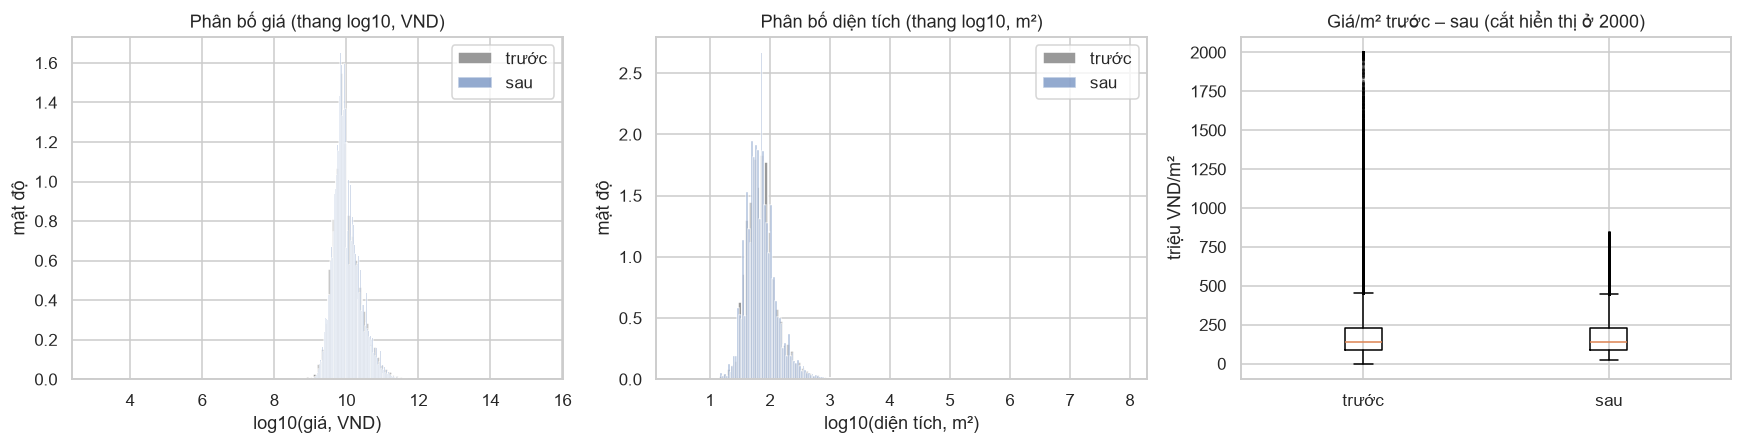

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
pr = raw["price_num"][raw["price_num"] > 0]
axes[0].hist(np.log10(pr), bins=120, color="0.6", label="trước", density=True)
axes[0].hist(np.log10(df["price_num"]), bins=120, alpha=.6, color="C0", label="sau", density=True)
axes[0].set(title="Phân bố giá (thang log10, VND)", xlabel="log10(giá, VND)", ylabel="mật độ")
axes[0].legend()
axes[1].hist(np.log10(raw["area"].clip(lower=1)), bins=120, color="0.6", label="trước", density=True)
axes[1].hist(np.log10(df["area"]), bins=60, alpha=.6, color="C0", label="sau", density=True)
axes[1].set(title="Phân bố diện tích (thang log10, m²)", xlabel="log10(diện tích, m²)", ylabel="mật độ")
axes[1].legend()
ppm2_raw = (raw["price_num"] / raw["area"] / 1e6)[raw["price_num"] > 0]
axes[2].boxplot([ppm2_raw.clip(upper=2000).dropna(), df["price_per_m2"]], showfliers=True,
                flierprops={"markersize": 1, "alpha": .2})
axes[2].set_xticks([1, 2], ["trước", "sau"])
axes[2].set(title="Giá/m² trước – sau (cắt hiển thị ở 2000)", ylabel="triệu VND/m²")
plt.tight_layout(); plt.savefig(FIG_DIR / "16_truoc_sau.png", bbox_inches="tight"); plt.show()

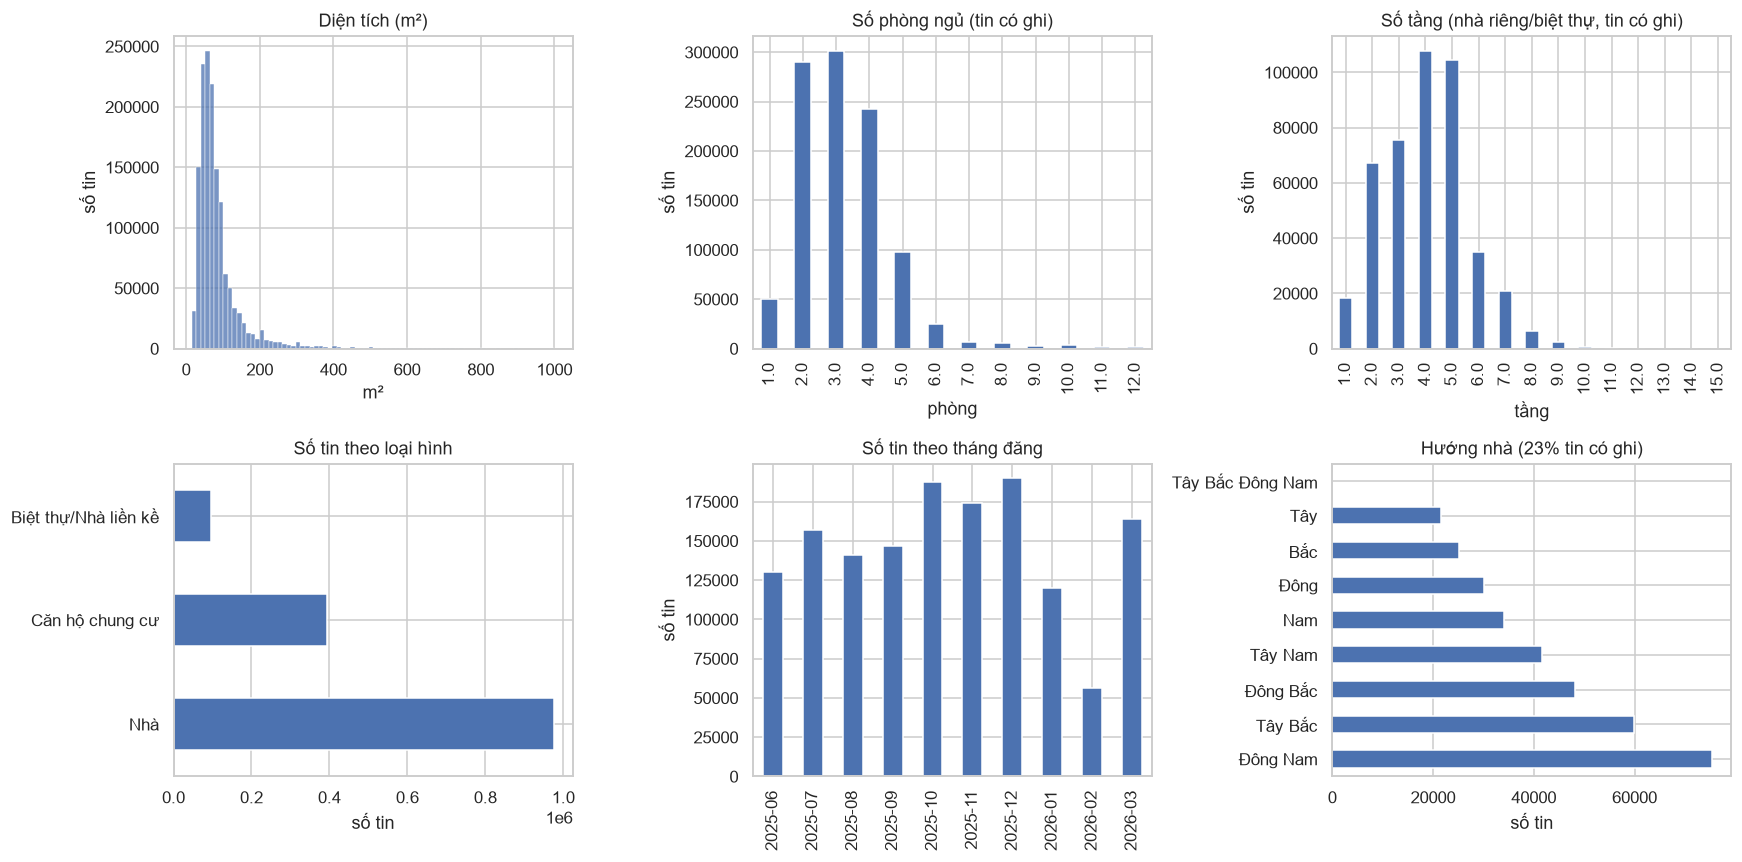

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
sns.histplot(df["area"], bins=80, ax=axes[0, 0]); axes[0, 0].set(title="Diện tích (m²)", xlabel="m²", ylabel="số tin")
df["bedroom_count"].value_counts().sort_index().head(12).plot.bar(ax=axes[0, 1], color="C0")
axes[0, 1].set(title="Số phòng ngủ (tin có ghi)", xlabel="phòng", ylabel="số tin")
df["floor_count"].value_counts().sort_index().plot.bar(ax=axes[0, 2], color="C0")
axes[0, 2].set(title="Số tầng (nhà riêng/biệt thự, tin có ghi)", xlabel="tầng", ylabel="số tin")
df["property_type_name"].value_counts().plot.barh(ax=axes[1, 0], color="C0")
axes[1, 0].set(title="Số tin theo loại hình", xlabel="số tin", ylabel="")
df["published_at"].dt.to_period("M").astype(str).value_counts().sort_index().plot.bar(ax=axes[1, 1], color="C0")
axes[1, 1].set(title="Số tin theo tháng đăng", xlabel="", ylabel="số tin")
dd = df["house_direction"].str.replace(" - ", " ", regex=False)
dd.where(dd.str.contains(",") == False).value_counts().plot.barh(ax=axes[1, 2], color="C0")
axes[1, 2].set(title="Hướng nhà (23% tin có ghi)", xlabel="số tin", ylabel="")
plt.tight_layout(); plt.savefig(FIG_DIR / "17_phan_bo_dac_trung.png", bbox_inches="tight"); plt.show()

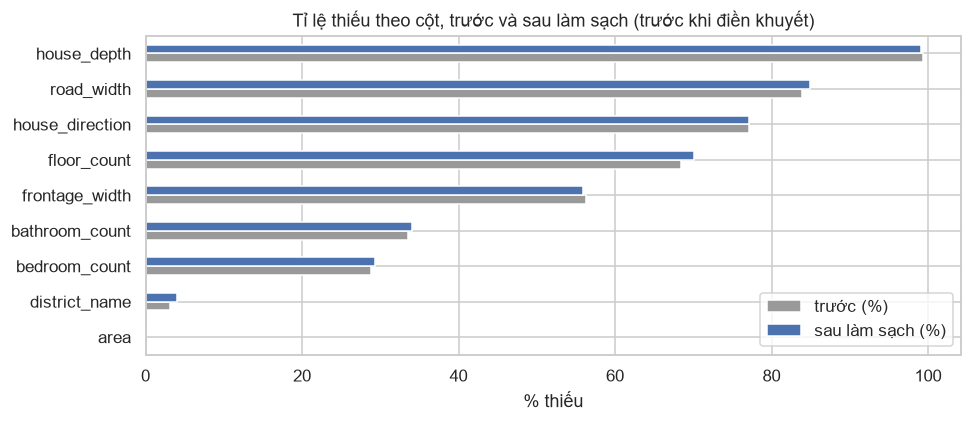

In [14]:
fig, ax = plt.subplots(figsize=(9, 4))
miss.sort_values("trước (%)").plot.barh(ax=ax, color=["0.6", "C0"])
ax.set(title="Tỉ lệ thiếu theo cột, trước và sau làm sạch (trước khi điền khuyết)", xlabel="% thiếu")
plt.tight_layout(); plt.savefig(FIG_DIR / "18_thieu_du_lieu.png", bbox_inches="tight"); plt.show()

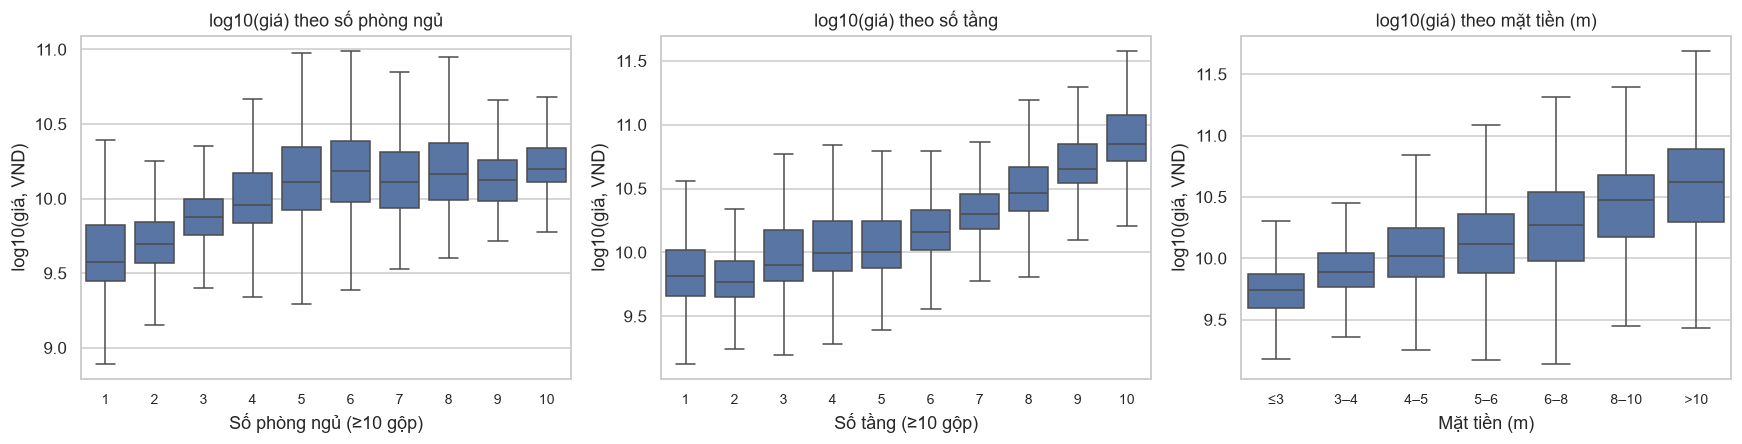

Spearman với log(giá):
area             0.498
bedroom_count    0.565
bathroom_count   0.533
floor_count      0.436
frontage_width   0.506
road_width       0.443


In [15]:
sub = df.sample(200_000, random_state=42)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, c, lab in [(axes[0], "bedroom_count", "Số phòng ngủ"), (axes[1], "floor_count", "Số tầng"),
                   (axes[2], "frontage_width", "Mặt tiền (m)")]:
    g = sub.dropna(subset=[c]).copy()
    if c == "frontage_width":       # biến liên tục → chia khoảng
        g[c] = pd.cut(g[c], [0, 3, 4, 5, 6, 8, 10, 50], labels=["≤3", "3–4", "4–5", "5–6", "6–8", "8–10", ">10"])
        xlab = lab
    else:
        g[c] = g[c].clip(upper=10).astype(int)
        xlab = lab + " (≥10 gộp)"
    sns.boxplot(data=g, x=c, y=np.log10(g["price_num"]), ax=ax, showfliers=False, color="C0")
    ax.set(title=f"log10(giá) theo {lab.lower()}", xlabel=xlab, ylabel="log10(giá, VND)")
    ax.tick_params(axis="x", labelsize=9)
plt.tight_layout(); plt.savefig(FIG_DIR / "19_gia_theo_dac_trung.png", bbox_inches="tight"); plt.show()
print("Spearman với log(giá):")
print(sub[["area", "bedroom_count", "bathroom_count", "floor_count", "frontage_width", "road_width"]]
      .corrwith(np.log(sub["price_num"]), method="spearman").round(3).to_string())